# PHASE 1 — DATA LOADING, CLEANING & QUALITY ASSESSMENT 

In [1]:
# ============================================
# PHASE 1: DATA LOADING & PREPROCESSING
# ============================================

import os
import re
import warnings
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
DATA_PATH = "emi_prediction_dataset.csv"

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset Shape:")
print(df.shape)

print("\nColumns:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

print("\nData Types:")
display(df.dtypes)

print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape:
(404800, 27)

Columns:
1. age
2. gender
3. marital_status
4. education
5. monthly_salary
6. employment_type
7. years_of_employment
8. company_type
9. house_type
10. monthly_rent
11. family_size
12. dependents
13. school_fees
14. college_fees
15. travel_expenses
16. groceries_utilities
17. other_monthly_expenses
18. existing_loans
19. current_emi_amount
20. credit_score
21. bank_balance
22. emergency_fund
23. emi_scenario
24. requested_amount
25. requested_tenure
26. emi_eligibility
27. max_monthly_emi

Data Types:


age                        object
gender                     object
marital_status             object
education                  object
monthly_salary             object
employment_type            object
years_of_employment       float64
company_type               object
house_type                 object
monthly_rent              float64
family_size                 int64
dependents                  int64
school_fees               float64
college_fees              float64
travel_expenses           float64
groceries_utilities       float64
other_monthly_expenses    float64
existing_loans             object
current_emi_amount        float64
credit_score              float64
bank_balance               object
emergency_fund            float64
emi_scenario               object
requested_amount          float64
requested_tenure            int64
emi_eligibility            object
max_monthly_emi           float64
dtype: object


Missing Values:


monthly_rent              2426
bank_balance              2426
credit_score              2420
education                 2404
emergency_fund            2351
marital_status               0
monthly_salary               0
years_of_employment          0
gender                       0
employment_type              0
age                          0
family_size                  0
house_type                   0
company_type                 0
dependents                   0
groceries_utilities          0
school_fees                  0
college_fees                 0
travel_expenses              0
current_emi_amount           0
existing_loans               0
other_monthly_expenses       0
emi_scenario                 0
requested_amount             0
requested_tenure             0
emi_eligibility              0
max_monthly_emi              0
dtype: int64


Duplicate Rows:
0


## Correct malformed numerical values

In [4]:
numeric_columns = [
    "age",
    "monthly_salary",
    "years_of_employment",
    "monthly_rent",
    "family_size",
    "dependents",
    "school_fees",
    "college_fees",
    "travel_expenses",
    "groceries_utilities",
    "other_monthly_expenses",
    "current_emi_amount",
    "credit_score",
    "bank_balance",
    "emergency_fund",
    "requested_amount",
    "requested_tenure",
    "max_monthly_emi"
]

def clean_numeric_value(value):
    """
    Converts malformed numeric strings such as
    '18000.0.0' into 18000.0.
    """
    
    if pd.isna(value):
        return np.nan
    
    value = str(value).strip()
    
    # Keep digits, minus sign and decimal point
    value = re.sub(r"[^0-9.\-]", "", value)
    
    # Handle multiple decimal points
    if value.count(".") > 1:
        parts = value.split(".")
        
        # Example: 18000.0.0 -> 18000.0
        value = parts[0] + "." + "".join(parts[1:])
        
        # If still malformed, retain first valid decimal
        try:
            return float(value)
        except:
            match = re.search(r"-?\d+\.?\d*", value)
            return float(match.group()) if match else np.nan
    
    try:
        return float(value)
    except:
        return np.nan


for col in numeric_columns:
    df[col] = df[col].apply(clean_numeric_value)

print("Numeric columns cleaned.")

Numeric columns cleaned.


##  Standardize categorical text

In [7]:

categorical_columns = [
    "gender",
    "marital_status",
    "education",
    "employment_type",
    "company_type",
    "house_type",
    "existing_loans",
    "emi_scenario",
    "emi_eligibility"
]

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip()


# Gender has inconsistent representations
gender_mapping = {
    "M": "Male",
    "MALE": "Male",
    "male": "Male",
    "Male": "Male",
    "F": "Female",
    "FEMALE": "Female",
    "female": "Female",
    "Female": "Female"
}

df["gender"] = df["gender"].map(gender_mapping)


print("Categorical values standardized.")

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Categorical values standardized.

gender:
gender
Male      242950
Female    161850
Name: count, dtype: int64

marital_status:
marital_status
Married    307837
Single      96963
Name: count, dtype: Int64

education:
education
Graduate         181015
Post Graduate    100314
High School       60732
Professional      60335
<NA>               2404
Name: count, dtype: Int64

employment_type:
employment_type
Private          283099
Government        81167
Self-employed     40534
Name: count, dtype: Int64

company_type:
company_type
Large Indian    121139
MNC             101409
Mid-size        101301
Startup          60706
Small            20245
Name: count, dtype: Int64

house_type:
house_type
Rented    161601
Own       142307
Family    100892
Name: count, dtype: Int64

existing_loans:
existing_loans
No     243227
Yes    161573
Name: count, dtype: Int64

emi_scenario:
emi_scenario
Home Appliances EMI        80988
Personal Loan EMI          80980
E-commerce Shopping EMI    80948
Education EMI 

## Handle missing values and duplicates

In [8]:
# Remove exact duplicate records
before_duplicates = len(df)

df = df.drop_duplicates().reset_index(drop=True)

after_duplicates = len(df)

print(
    f"Removed {before_duplicates - after_duplicates} duplicate rows."
)


# Numeric missing values -> median
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())


# Categorical missing values -> mode
for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])


print("\nMissing values after cleaning:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

Removed 0 duplicate rows.

Missing values after cleaning:


age                    0
gender                 0
marital_status         0
education              0
monthly_salary         0
employment_type        0
years_of_employment    0
company_type           0
house_type             0
monthly_rent           0
dtype: int64

In [9]:
print("========== DATA QUALITY REPORT ==========")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["emi_eligibility"].value_counts())

print("\nRegression target statistics:")
display(df["max_monthly_emi"].describe())

print("\nCredit score range:")
print(df["credit_score"].min(), "-", df["credit_score"].max())

print("\nRequested amount range:")
print(df["requested_amount"].min(), "-", df["requested_amount"].max())

print("\nRequested tenure range:")
print(df["requested_tenure"].min(), "-", df["requested_tenure"].max())

========== DATA QUALITY REPORT ==========
Rows: 404800
Columns: 27

Missing values: 0
Duplicate rows: 0

Target distribution:


emi_eligibility
Not_Eligible    312868
Eligible         74444
High_Risk        17488
Name: count, dtype: Int64


Regression target statistics:


count    404800.000000
mean       6763.602156
std        7741.263317
min         500.000000
25%         500.000000
50%        4211.200000
75%        9792.000000
max       91040.400000
Name: max_monthly_emi, dtype: float64


Credit score range:
0.0 - 1200.0

Requested amount range:
10000.0 - 1500000.0

Requested tenure range:
3.0 - 84.0


# PHASE 2 — EDA & FEATURE ENGINEERING

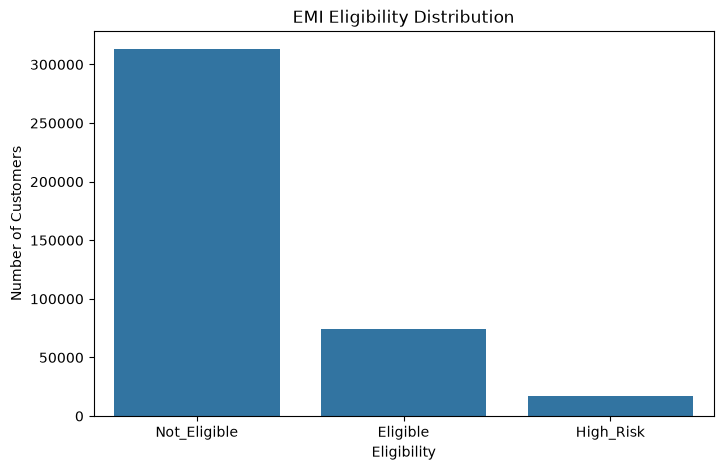

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="emi_eligibility"
)

plt.title("EMI Eligibility Distribution")
plt.xlabel("Eligibility")
plt.ylabel("Number of Customers")

plt.show()

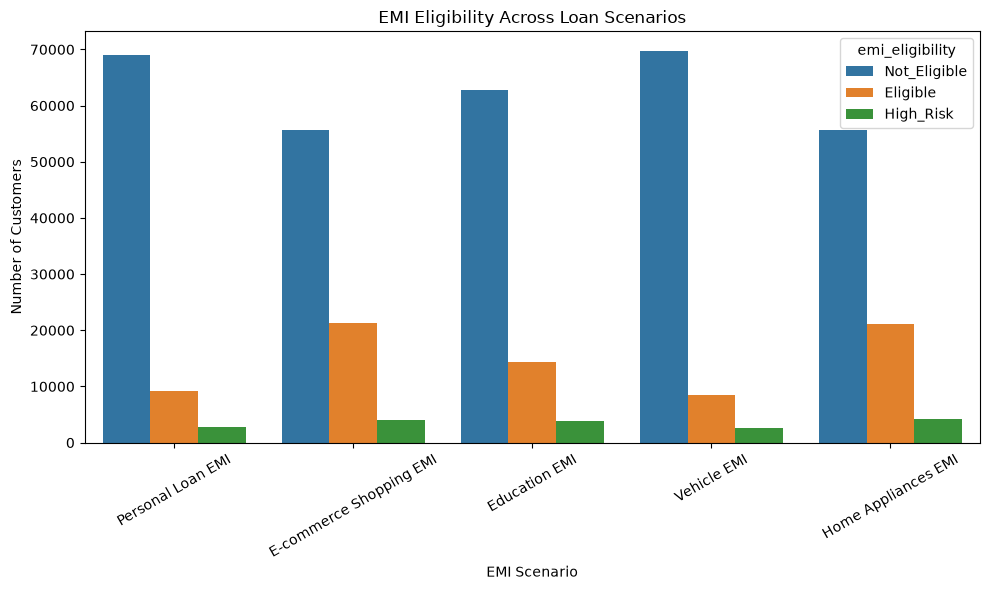

In [11]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="emi_scenario",
    hue="emi_eligibility"
)

plt.xticks(rotation=30)

plt.title("EMI Eligibility Across Loan Scenarios")
plt.xlabel("EMI Scenario")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [13]:
financial_columns = [
    "monthly_salary",
    "current_emi_amount",
    "bank_balance",
    "emergency_fund",
    "requested_amount",
    "max_monthly_emi"
]

display(
    df[financial_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
monthly_salary,404800.0,59501.887530,43367.251049,3967.0,35400.0,51700.0,73000.0,499970.0
current_emi_amount,404800.0,4543.407609,7034.901139,0.0,0.0,0.0,8000.0,56300.0
bank_balance,404800.0,241406.791502,182713.154715,0.0,104900.0,196000.0,330000.0,1717300.0
emergency_fund,404800.0,96636.813488,81154.854810,1400.0,38600.0,74000.0,130200.0,891500.0
requested_amount,404800.0,370855.400198,345194.517904,10000.0,124000.0,236000.0,494000.0,1500000.0
max_monthly_emi,404800.0,6763.602156,7741.263317,500.0,500.0,4211.2,9792.0,91040.4


In [14]:
# Total monthly expenses
df["total_monthly_expenses"] = (
    df["monthly_rent"]
    + df["school_fees"]
    + df["college_fees"]
    + df["travel_expenses"]
    + df["groceries_utilities"]
    + df["other_monthly_expenses"]
)


# Total financial burden
df["total_debt_burden"] = (
    df["current_emi_amount"]
    + df["total_monthly_expenses"]
)


# Debt-to-income ratio
df["debt_to_income_ratio"] = (
    df["total_debt_burden"]
    / df["monthly_salary"].replace(0, np.nan)
)


# Expense-to-income ratio
df["expense_to_income_ratio"] = (
    df["total_monthly_expenses"]
    / df["monthly_salary"].replace(0, np.nan)
)


# Current EMI-to-income ratio
df["current_emi_to_income"] = (
    df["current_emi_amount"]
    / df["monthly_salary"].replace(0, np.nan)
)


# Requested loan to salary
df["loan_to_salary_ratio"] = (
    df["requested_amount"]
    / df["monthly_salary"].replace(0, np.nan)
)


# Bank balance relative to salary
df["balance_to_salary_ratio"] = (
    df["bank_balance"]
    / df["monthly_salary"].replace(0, np.nan)
)


# Emergency fund relative to expenses
df["emergency_coverage_ratio"] = (
    df["emergency_fund"]
    / df["total_monthly_expenses"].replace(0, np.nan)
)


# Remaining monthly income
df["remaining_income"] = (
    df["monthly_salary"]
    - df["total_debt_burden"]
)


# Requested EMI estimate
df["estimated_requested_emi"] = (
    df["requested_amount"]
    / df["requested_tenure"].replace(0, np.nan)
)


# Affordability ratio
df["affordability_ratio"] = (
    df["max_monthly_emi"]
    / df["monthly_salary"].replace(0, np.nan)
)


# Replace infinite values
df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)


# Fill engineered missing values
engineered_columns = [
    "debt_to_income_ratio",
    "expense_to_income_ratio",
    "current_emi_to_income",
    "loan_to_salary_ratio",
    "balance_to_salary_ratio",
    "emergency_coverage_ratio",
    "remaining_income",
    "estimated_requested_emi",
    "affordability_ratio"
]

for col in engineered_columns:
    df[col] = df[col].fillna(df[col].median())


print("Feature engineering completed.")
print("New dataset shape:", df.shape)

Feature engineering completed.
New dataset shape: (404800, 38)


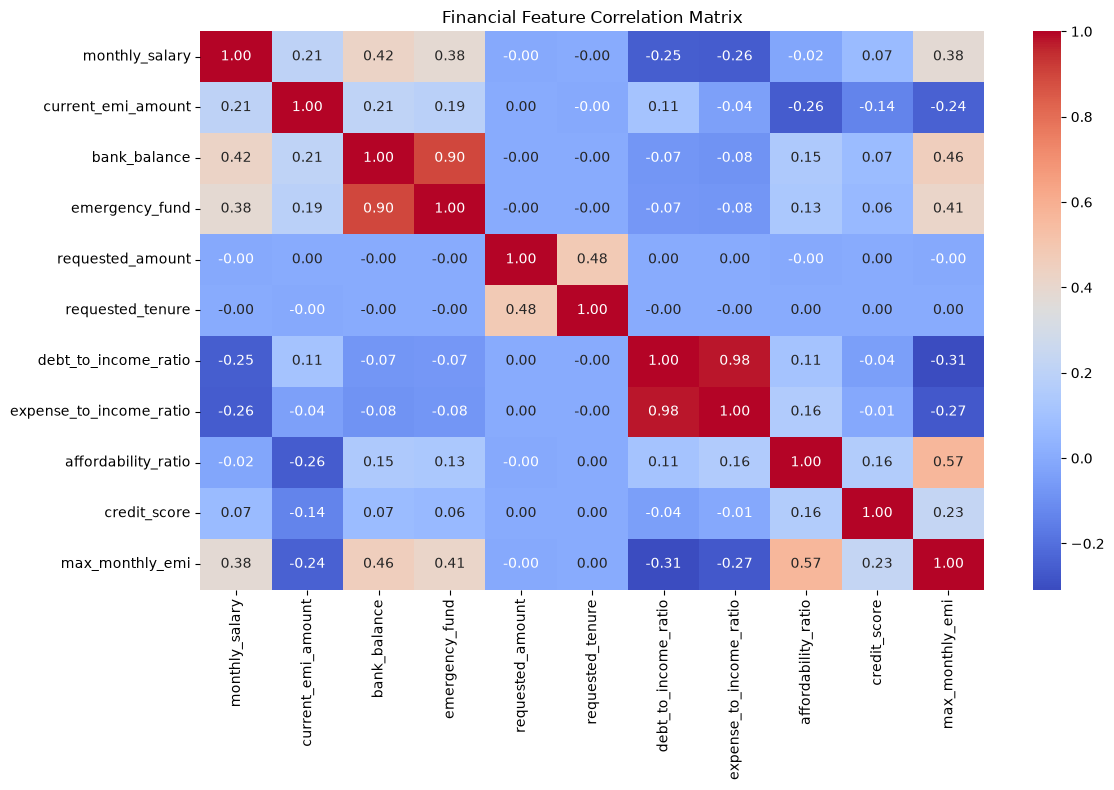

In [15]:
correlation_features = [
    "monthly_salary",
    "current_emi_amount",
    "bank_balance",
    "emergency_fund",
    "requested_amount",
    "requested_tenure",
    "debt_to_income_ratio",
    "expense_to_income_ratio",
    "affordability_ratio",
    "credit_score",
    "max_monthly_emi"
]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[correlation_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Financial Feature Correlation Matrix")
plt.tight_layout()

plt.show()

# PHASE 3 — CLASSIFICATION MODEL DEVELOPMENT

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

from xgboost import XGBClassifier


classification_target = "emi_eligibility"

X_class = df.drop(
    columns=[
        "emi_eligibility",
        "max_monthly_emi"
    ]
)

y_class = df[classification_target]


# Encode target
label_encoder = LabelEncoder()

y_class_encoded = label_encoder.fit_transform(y_class)

print("Classes:")
for i, cls in enumerate(label_encoder.classes_):
    print(i, "->", cls)

Classes:
0 -> Eligible
1 -> High_Risk
2 -> Not_Eligible


In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_class,
    y_class_encoded,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_class_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (283360, 36)
Validation: (60720, 36)
Testing: (60720, 36)


## Preprocessing pipeline

In [18]:
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()


numeric_transformer = Pipeline(
    steps=[("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])


categorical_transformer = Pipeline(
    steps=[("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))])


preprocessor = ColumnTransformer(
    transformers=[("num",numeric_transformer,numerical_features),("cat",categorical_transformer,categorical_features)])

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 28
Categorical features: 8


## Definfing Classification Models

In [19]:
classification_models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

print("Classification models created.")

Classification models created.


In [20]:
classification_results = []
classification_pipelines = {}

for name, model in classification_models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)

    accuracy = accuracy_score(
        y_val,
        y_pred
    )

    precision = precision_score(
        y_val,
        y_pred,
        average="weighted"
    )

    recall = recall_score(
        y_val,
        y_pred,
        average="weighted"
    )

    f1 = f1_score(
        y_val,
        y_pred,
        average="weighted"
    )

    roc_auc = roc_auc_score(
        y_val,
        y_prob,
        multi_class="ovr",
        average="weighted"
    )

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

    classification_pipelines[name] = pipeline

    print(f"{name} completed.")


classification_results_df = pd.DataFrame(
    classification_results
).sort_values(
    "F1 Score",
    ascending=False
)

display(classification_results_df)


Training Logistic Regression...
Logistic Regression completed.

Training Random Forest...
Random Forest completed.

Training XGBoost...
XGBoost completed.


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.988356,0.988098,0.988356,0.988189,0.999688
1,Random Forest,0.960540,0.957423,0.960540,0.948883,0.998160
0,Logistic Regression,0.952767,0.944509,0.952767,0.945624,0.994193


## CLASSIFICATION REPORT

In [22]:
best_classification_name = (
    classification_results_df
    .iloc[0]["Model"]
)

best_classification_model = (
    classification_pipelines[
        best_classification_name
    ]
)

y_test_pred = best_classification_model.predict(X_test)

print(
    f"Best Classification Model: "
    f"{best_classification_name}"
)

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_
    )
)

Best Classification Model: XGBoost
              precision    recall  f1-score   support

    Eligible       0.98      0.99      0.99     11167
   High_Risk       0.89      0.84      0.87      2623
Not_Eligible       0.99      1.00      1.00     46930

    accuracy                           0.99     60720
   macro avg       0.96      0.94      0.95     60720
weighted avg       0.99      0.99      0.99     60720



# PHASE 4 — REGRESSION MODEL DEVELOPMENT

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

from xgboost import XGBRegressor


regression_target = "max_monthly_emi"

X_reg = df.drop(
    columns=[
        "emi_eligibility",
        "max_monthly_emi"
    ]
)

y_reg = df[regression_target]


X_train_r, X_temp_r, y_train_r, y_temp_r = train_test_split(
    X_reg,
    y_reg,
    test_size=0.30,
    random_state=RANDOM_STATE
)

X_val_r, X_test_r, y_val_r, y_test_r = train_test_split(
    X_temp_r,
    y_temp_r,
    test_size=0.50,
    random_state=RANDOM_STATE
)

print("Training:", X_train_r.shape)
print("Validation:", X_val_r.shape)
print("Testing:", X_test_r.shape)

Training: (283360, 36)
Validation: (60720, 36)
Testing: (60720, 36)


In [23]:
regression_models = {

    "Linear Regression": LinearRegression(),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "XGBoost Regressor": XGBRegressor(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

regression_pipelines = {}
regression_results = []

for name, model in regression_models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[("preprocessor", preprocessor),("model", model)])

    pipeline.fit(X_train_r,y_train_r)
    y_pred = pipeline.predict(X_val_r)
    rmse = np.sqrt(mean_squared_error(y_val_r,y_pred))
    mae = mean_absolute_error(y_val_r,y_pred)
    r2 = r2_score(y_val_r,y_pred)
    mape = mean_absolute_percentage_error(y_val_r,y_pred) * 100
    regression_results.append({"Model": name,"RMSE": rmse,"MAE": mae,"R2 Score": r2,"MAPE (%)": mape})
    regression_pipelines[name] = pipeline
    print(f"{name} completed.")


regression_results_df = pd.DataFrame(regression_results).sort_values("RMSE")

display(regression_results_df)


Training Linear Regression...
Linear Regression completed.

Training Random Forest Regressor...
Random Forest Regressor completed.

Training XGBoost Regressor...
XGBoost Regressor completed.


,Model,RMSE,MAE,R2 Score,MAPE (%)
1,Random Forest Regressor,330.758052,63.224786,0.998175,1.045204
2,XGBoost Regressor,385.912853,101.760402,0.997515,1.999702
0,Linear Regression,3466.827437,2198.915173,0.799469,134.237257


In [24]:
best_regression_name = (
    regression_results_df
    .iloc[0]["Model"]
)

best_regression_model = (regression_pipelines[best_regression_name])
y_test_reg_pred = best_regression_model.predict(X_test_r)
test_rmse = np.sqrt(mean_squared_error(y_test_r,y_test_reg_pred))
test_mae = mean_absolute_error(y_test_r,y_test_reg_pred)
test_r2 = r2_score(y_test_r,y_test_reg_pred)
test_mape = (mean_absolute_percentage_error(y_test_r,y_test_reg_pred) * 100)

print("Best Regression Model:")
print(best_regression_name)

print("\nTest RMSE:", test_rmse)
print("Test MAE:", test_mae)
print("Test R²:", test_r2)
print("Test MAPE:", test_mape, "%")

Best Regression Model:
Random Forest Regressor

Test RMSE: 344.7572916692022
Test MAE: 64.83493547482631
Test R²: 0.9980002209128395
Test MAPE: 1.1113867356838867 %


# PHASE 5 — MLFLOW EXPERIMENT TRACKING

In [33]:
# ============================================
# MLFLOW - CLASSIFICATION EXPERIMENTS
# ============================================

mlflow.set_experiment(
    "EMIPredict_Classification"
)

for _, row in classification_results_df.iterrows():

    model_name = row["Model"]

    with mlflow.start_run(
        run_name=model_name
    ):

        model = classification_pipelines[model_name]

        # -----------------------------
        # Parameters
        # -----------------------------
        mlflow.log_param(
            "model",
            model_name
        )

        mlflow.log_param(
            "training_rows",
            len(X_train)
        )

        mlflow.log_param(
            "features",
            X_train.shape[1]
        )

        # -----------------------------
        # Metrics
        # -----------------------------
        mlflow.log_metric(
            "accuracy",
            row["Accuracy"]
        )

        mlflow.log_metric(
            "precision",
            row["Precision"]
        )

        mlflow.log_metric(
            "recall",
            row["Recall"]
        )

        mlflow.log_metric(
            "f1_score",
            row["F1 Score"]
        )

        mlflow.log_metric(
            "roc_auc",
            row["ROC-AUC"]
        )

        # -----------------------------
        # Save model
        # -----------------------------
        mlflow.sklearn.log_model(
            model,
            "classification_model",
            serialization_format="pickle"
        )

        print(f"{model_name} logged successfully.")

print("All classification experiments logged.")

2026/08/25 21:32:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/08/25 21:32:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost logged successfully.


2026/08/25 21:33:06 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/08/25 21:33:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest logged successfully.


2026/08/25 21:33:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/08/25 21:33:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression logged successfully.
All classification experiments logged.


In [34]:
# ============================================
# MLFLOW - REGRESSION EXPERIMENTS
# ============================================

mlflow.set_experiment(
    "EMIPredict_Regression"
)

for _, row in regression_results_df.iterrows():

    model_name = row["Model"]

    with mlflow.start_run(
        run_name=model_name
    ):

        model = regression_pipelines[model_name]

        # -----------------------------
        # Parameters
        # -----------------------------
        mlflow.log_param(
            "model",
            model_name
        )

        mlflow.log_param(
            "training_rows",
            len(X_train_r)
        )

        mlflow.log_param(
            "features",
            X_train_r.shape[1]
        )

        # -----------------------------
        # Metrics
        # -----------------------------
        mlflow.log_metric(
            "rmse",
            row["RMSE"]
        )

        mlflow.log_metric(
            "mae",
            row["MAE"]
        )

        mlflow.log_metric(
            "r2_score",
            row["R2 Score"]
        )

        mlflow.log_metric(
            "mape",
            row["MAPE (%)"]
        )

        # -----------------------------
        # Save model
        # -----------------------------
        mlflow.sklearn.log_model(
            model,
            "regression_model",
            serialization_format="pickle"
        )

        print(f"{model_name} logged successfully.")

print("All regression experiments logged.")

2026/08/25 21:33:50 INFO mlflow.tracking.fluent: Experiment with name 'EMIPredict_Regression' does not exist. Creating a new experiment.
2026/08/25 21:33:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/08/25 21:33:50 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest Regressor logged successfully.


2026/08/25 21:34:10 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/08/25 21:34:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/08/25 21:34:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


XGBoost Regressor logged successfully.


2026/08/25 21:34:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Linear Regression logged successfully.
All regression experiments logged.


# PHASE 6 — SAVE PRODUCTION ARTIFACTS

In [26]:
# ============================================
# PHASE 6: PRODUCTION ARTIFACTS
# ============================================

os.makedirs(
    "models",
    exist_ok=True
)

os.makedirs(
    "artifacts",
    exist_ok=True
)

In [27]:
joblib.dump(
    best_classification_model,
    "models/best_classification_model.pkl"
)

joblib.dump(
    best_regression_model,
    "models/best_regression_model.pkl"
)

joblib.dump(
    label_encoder,
    "models/classification_label_encoder.pkl"
)

print("Models saved successfully.")

Models saved successfully.


In [28]:
feature_info = {
    "classification_features": X_class.columns.tolist(),
    "regression_features": X_reg.columns.tolist(),
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "classification_classes": label_encoder.classes_.tolist(),
    "best_classification_model": best_classification_name,
    "best_regression_model": best_regression_name
}

joblib.dump(
    feature_info,
    "models/feature_info.pkl"
)

print("Feature information saved.")

Feature information saved.


In [29]:
classification_results_df.to_csv(
    "artifacts/classification_results.csv",
    index=False
)

regression_results_df.to_csv(
    "artifacts/regression_results.csv",
    index=False
)

print("Model comparison results saved.")

Model comparison results saved.


In [30]:
print("=" * 60)
print("EMIPredict AI - MODEL DEVELOPMENT SUMMARY")
print("=" * 60)

print("\nDataset:")
print(f"Records: {len(df):,}")
print(f"Features: {len(df.columns)}")

print("\nClassification:")
print("Best Model:", best_classification_name)

display(
    classification_results_df
)

print("\nRegression:")
print("Best Model:", best_regression_name)

display(
    regression_results_df
)

print("\nProduction files:")
print("- models/best_classification_model.pkl")
print("- models/best_regression_model.pkl")
print("- models/classification_label_encoder.pkl")
print("- models/feature_info.pkl")
print("- artifacts/classification_results.csv")
print("- artifacts/regression_results.csv")

EMIPredict AI - MODEL DEVELOPMENT SUMMARY

Dataset:
Records: 404,800
Features: 38

Classification:
Best Model: XGBoost


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.988356,0.988098,0.988356,0.988189,0.999688
1,Random Forest,0.960540,0.957423,0.960540,0.948883,0.998160
0,Logistic Regression,0.952767,0.944509,0.952767,0.945624,0.994193



Regression:
Best Model: Random Forest Regressor


,Model,RMSE,MAE,R2 Score,MAPE (%)
1,Random Forest Regressor,330.758052,63.224786,0.998175,1.045204
2,XGBoost Regressor,385.912853,101.760402,0.997515,1.999702
0,Linear Regression,3466.827437,2198.915173,0.799469,134.237257



Production files:
- models/best_classification_model.pkl
- models/best_regression_model.pkl
- models/classification_label_encoder.pkl
- models/feature_info.pkl
- artifacts/classification_results.csv
- artifacts/regression_results.csv


In [37]:
import mlflow
print(mlflow.get_tracking_uri())

sqlite:///C:/Users/Madhu/Desktop/LABMENTIX/Project%205/mlflow.db


In [38]:
# ============================================
# PHASE 6: FINAL MODEL EVALUATION
# ============================================

print("=" * 60)
print("FINAL MODEL EVALUATION")
print("=" * 60)


# ============================================
# CLASSIFICATION
# ============================================

best_classification_model = classification_pipelines[
    best_classification_name
]

y_test_class_pred = best_classification_model.predict(
    X_test
)

y_test_class_prob = (
    best_classification_model.predict_proba(X_test)
)


classification_test_accuracy = accuracy_score(
    y_test,
    y_test_class_pred
)

classification_test_precision = precision_score(
    y_test,
    y_test_class_pred,
    average="weighted"
)

classification_test_recall = recall_score(
    y_test,
    y_test_class_pred,
    average="weighted"
)

classification_test_f1 = f1_score(
    y_test,
    y_test_class_pred,
    average="weighted"
)

classification_test_roc_auc = roc_auc_score(
    y_test,
    y_test_class_prob,
    multi_class="ovr",
    average="weighted"
)


print("\nCLASSIFICATION RESULTS")
print("-" * 40)
print("Best Model :", best_classification_name)
print("Accuracy   :", classification_test_accuracy)
print("Precision  :", classification_test_precision)
print("Recall     :", classification_test_recall)
print("F1 Score   :", classification_test_f1)
print("ROC-AUC    :", classification_test_roc_auc)


# ============================================
# REGRESSION
# ============================================

best_regression_model = regression_pipelines[
    best_regression_name
]

y_test_reg_pred = best_regression_model.predict(
    X_test_r
)

regression_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_r,
        y_test_reg_pred
    )
)

regression_test_mae = mean_absolute_error(
    y_test_r,
    y_test_reg_pred
)

regression_test_r2 = r2_score(
    y_test_r,
    y_test_reg_pred
)

regression_test_mape = (
    mean_absolute_percentage_error(
        y_test_r,
        y_test_reg_pred
    ) * 100
)


print("\nREGRESSION RESULTS")
print("-" * 40)
print("Best Model :", best_regression_name)
print("RMSE       :", regression_test_rmse)
print("MAE        :", regression_test_mae)
print("R²         :", regression_test_r2)
print("MAPE       :", regression_test_mape, "%")

FINAL MODEL EVALUATION

CLASSIFICATION RESULTS
----------------------------------------
Best Model : XGBoost
Accuracy   : 0.9874505928853755
Precision  : 0.9871888794350758
Recall     : 0.9874505928853755
F1 Score   : 0.9872854727866921
ROC-AUC    : 0.9996904816717247

REGRESSION RESULTS
----------------------------------------
Best Model : Random Forest Regressor
RMSE       : 344.7572916692022
MAE        : 64.8349354748263
R²         : 0.9980002209128395
MAPE       : 1.1113867356838831 %


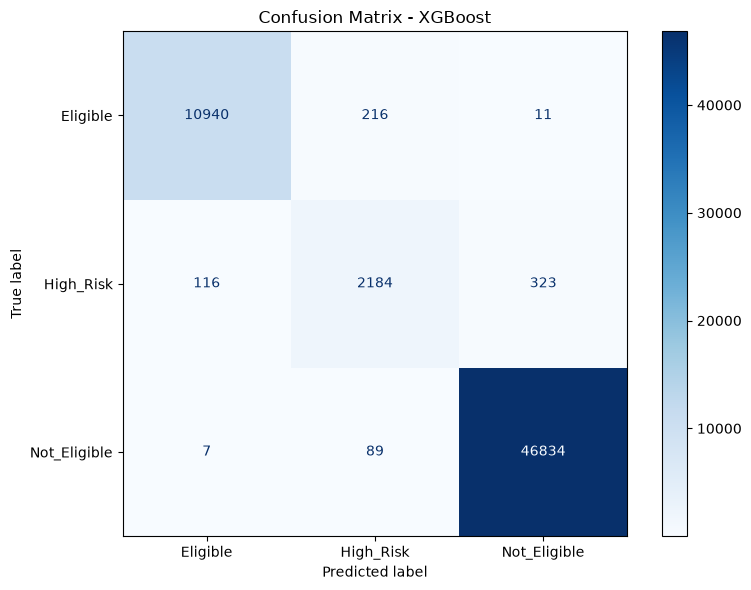

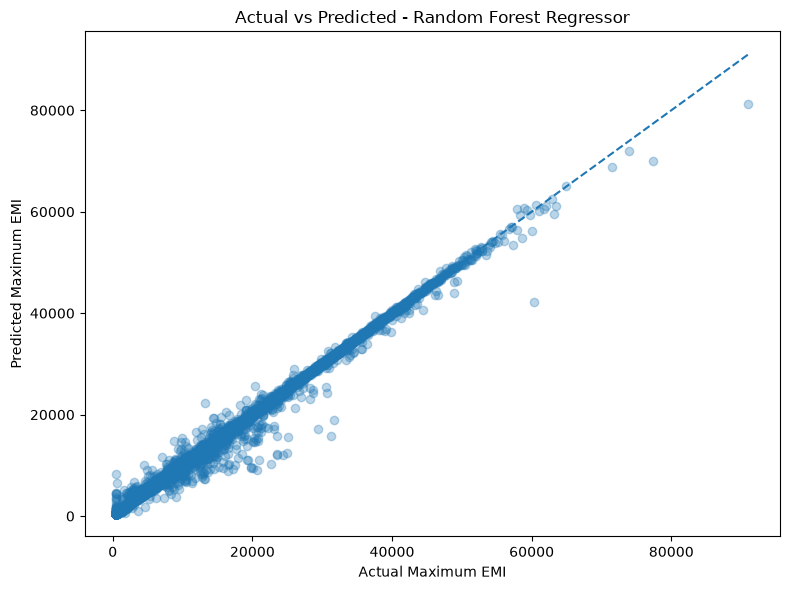

In [39]:
# ============================================
# CLASSIFICATION CONFUSION MATRIX
# ============================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_test_class_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    cmap="Blues"
)

plt.title(
    f"Confusion Matrix - {best_classification_name}"
)

plt.tight_layout()
plt.show()


# ============================================
# REGRESSION ACTUAL VS PREDICTED
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_r,
    y_test_reg_pred,
    alpha=0.3
)

# Perfect prediction line
min_value = min(
    y_test_r.min(),
    y_test_reg_pred.min()
)

max_value = max(
    y_test_r.max(),
    y_test_reg_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Maximum EMI")
plt.ylabel("Predicted Maximum EMI")

plt.title(
    f"Actual vs Predicted - {best_regression_name}"
)

plt.tight_layout()
plt.show()

In [40]:
# ============================================
# CREATE PRODUCTION DIRECTORIES
# ============================================

import os

directories = [
    "models",
    "artifacts",
    "data",
    "reports"
]

for directory in directories:
    os.makedirs(
        directory,
        exist_ok=True
    )

print("Production directories created.")

# ============================================
# SAVE BEST MODELS
# ============================================

joblib.dump(
    best_classification_model,
    "models/best_classification_model.pkl"
)

joblib.dump(
    best_regression_model,
    "models/best_regression_model.pkl"
)

joblib.dump(
    label_encoder,
    "models/classification_label_encoder.pkl"
)

print("Best models saved successfully.")


# ============================================
# SAVE FEATURE INFORMATION
# ============================================

feature_info = {

    "classification_target":
        "emi_eligibility",

    "regression_target":
        "max_monthly_emi",

    "classification_features":
        X_class.columns.tolist(),

    "regression_features":
        X_reg.columns.tolist(),

    "categorical_features":
        categorical_features,

    "numerical_features":
        numerical_features,

    "classification_classes":
        label_encoder.classes_.tolist(),

    "best_classification_model":
        best_classification_name,

    "best_regression_model":
        best_regression_name,

    "random_state":
        RANDOM_STATE
}


joblib.dump(
    feature_info,
    "models/feature_info.pkl"
)

print("Feature information saved.")



# ============================================
# SAVE MODEL COMPARISON RESULTS
# ============================================

classification_results_df.to_csv(
    "reports/classification_model_comparison.csv",
    index=False
)

regression_results_df.to_csv(
    "reports/regression_model_comparison.csv",
    index=False
)


# Final test metrics

final_classification_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Value": [
        classification_test_accuracy,
        classification_test_precision,
        classification_test_recall,
        classification_test_f1,
        classification_test_roc_auc
    ]
})


final_regression_metrics = pd.DataFrame({
    "Metric": [
        "RMSE",
        "MAE",
        "R2 Score",
        "MAPE (%)"
    ],
    "Value": [
        regression_test_rmse,
        regression_test_mae,
        regression_test_r2,
        regression_test_mape
    ]
})


final_classification_metrics.to_csv(
    "reports/final_classification_metrics.csv",
    index=False
)

final_regression_metrics.to_csv(
    "reports/final_regression_metrics.csv",
    index=False
)

print("Reports saved successfully.")



# ============================================
# SAVE CLEANED DATASET
# ============================================

cleaned_data_path = (
    "data/emi_prediction_cleaned.csv"
)

df.to_csv(
    cleaned_data_path,
    index=False
)

print(
    f"Cleaned dataset saved to: "
    f"{cleaned_data_path}"
)

print(
    f"Final dataset shape: {df.shape}"
)

# ============================================
# VERIFY PRODUCTION ARTIFACTS
# ============================================

print("=" * 60)
print("PRODUCTION ARTIFACTS")
print("=" * 60)

for root, dirs, files in os.walk("."):
    
    # Ignore Jupyter/system folders
    if ".ipynb_checkpoints" in root:
        continue

    for file in files:
        if (
            file.endswith(".pkl")
            or file.endswith(".csv")
        ):
            path = os.path.join(
                root,
                file
            )

            print(path)

Production directories created.
Best models saved successfully.
Feature information saved.
Reports saved successfully.
Cleaned dataset saved to: data/emi_prediction_cleaned.csv
Final dataset shape: (404800, 38)
PRODUCTION ARTIFACTS
.\emi_prediction_dataset.csv
.\data\emi_prediction_cleaned.csv
.\mlruns\1\models\m-59053935d5f0411093427591dbd6e3e8\artifacts\model.pkl
.\mlruns\1\models\m-6664da30a0ac4ff5b6b64b5d1b775c3a\artifacts\model.pkl
.\mlruns\1\models\m-d2982a9f2ecb4c019b2955bb22faff64\artifacts\model.pkl
.\mlruns\2\models\m-1f7b0fec31c84fc48b7b39f80abeb08f\artifacts\model.pkl
.\mlruns\2\models\m-6c83f22e34e14f4ca0e7ff6c39e8252b\artifacts\model.pkl
.\mlruns\2\models\m-87a99bb82ffe4d5f8105ad7ec29dd53d\artifacts\model.pkl
.\models\best_classification_model.pkl
.\models\best_regression_model.pkl
.\models\classification_label_encoder.pkl
.\models\feature_info.pkl
.\reports\classification_model_comparison.csv
.\reports\final_classification_metrics.csv
.\reports\final_regression_metrics.c

In [41]:
# ============================================
# TEST SAVED MODELS
# ============================================

loaded_classification_model = joblib.load(
    "models/best_classification_model.pkl"
)

loaded_regression_model = joblib.load(
    "models/best_regression_model.pkl"
)

loaded_label_encoder = joblib.load(
    "models/classification_label_encoder.pkl"
)

loaded_feature_info = joblib.load(
    "models/feature_info.pkl"
)


print("Models loaded successfully!")

print(
    "\nClassification model:",
    loaded_feature_info["best_classification_model"]
)

print(
    "Regression model:",
    loaded_feature_info["best_regression_model"]
)

print(
    "Classification classes:",
    loaded_feature_info["classification_classes"]
)

Models loaded successfully!

Classification model: XGBoost
Regression model: Random Forest Regressor
Classification classes: ['Eligible', 'High_Risk', 'Not_Eligible']


In [42]:
# ============================================
# REAL CUSTOMER PREDICTION TEST
# ============================================

sample_customer = X_test.iloc[[0]]

print("Sample input:")
display(sample_customer)


# Classification
classification_prediction = (
    loaded_classification_model.predict(
        sample_customer
    )
)

classification_probability = (
    loaded_classification_model.predict_proba(
        sample_customer
    )
)


predicted_class = (
    loaded_label_encoder.inverse_transform(
        classification_prediction
    )[0]
)


# Regression
regression_prediction = (
    loaded_regression_model.predict(
        X_test_r.iloc[[0]]
    )[0]
)


print("\n" + "=" * 50)
print("PREDICTION RESULT")
print("=" * 50)

print(
    "EMI Eligibility:",
    predicted_class
)

print(
    "Predicted Maximum Monthly EMI: ₹",
    round(regression_prediction, 2)
)

print("\nClass probabilities:")

for class_name, probability in zip(
    loaded_label_encoder.classes_,
    classification_probability[0]
):
    
    print(
        f"{class_name}: "
        f"{probability:.2%}"
    )

Sample input:


,age,gender,marital_status,education,monthly_salary,employment_type,years_of_employment,company_type,house_type,monthly_rent,...,total_debt_burden,debt_to_income_ratio,expense_to_income_ratio,current_emi_to_income,loan_to_salary_ratio,balance_to_salary_ratio,emergency_coverage_ratio,remaining_income,estimated_requested_emi,affordability_ratio
257232,32.0,Female,Single,Post Graduate,161200.0,Private,0.8,Mid-size,Family,0.0,...,93600.0,0.580645,0.580645,0.0,8.98263,7.014268,6.824786,67600.0,37128.205128,0.184516



PREDICTION RESULT
EMI Eligibility: Not_Eligible
Predicted Maximum Monthly EMI: ₹ 1036.2

Class probabilities:
Eligible: 0.00%
High_Risk: 0.11%
Not_Eligible: 99.89%


In [43]:
print(feature_info["classification_features"])
print(len(feature_info["classification_features"]))

['age', 'gender', 'marital_status', 'education', 'monthly_salary', 'employment_type', 'years_of_employment', 'company_type', 'house_type', 'monthly_rent', 'family_size', 'dependents', 'school_fees', 'college_fees', 'travel_expenses', 'groceries_utilities', 'other_monthly_expenses', 'existing_loans', 'current_emi_amount', 'credit_score', 'bank_balance', 'emergency_fund', 'emi_scenario', 'requested_amount', 'requested_tenure', 'total_monthly_expenses', 'total_debt_burden', 'debt_to_income_ratio', 'expense_to_income_ratio', 'current_emi_to_income', 'loan_to_salary_ratio', 'balance_to_salary_ratio', 'emergency_coverage_ratio', 'remaining_income', 'estimated_requested_emi', 'affordability_ratio']
36


In [44]:
print(feature_info["regression_features"])
print(len(feature_info["regression_features"]))

['age', 'gender', 'marital_status', 'education', 'monthly_salary', 'employment_type', 'years_of_employment', 'company_type', 'house_type', 'monthly_rent', 'family_size', 'dependents', 'school_fees', 'college_fees', 'travel_expenses', 'groceries_utilities', 'other_monthly_expenses', 'existing_loans', 'current_emi_amount', 'credit_score', 'bank_balance', 'emergency_fund', 'emi_scenario', 'requested_amount', 'requested_tenure', 'total_monthly_expenses', 'total_debt_burden', 'debt_to_income_ratio', 'expense_to_income_ratio', 'current_emi_to_income', 'loan_to_salary_ratio', 'balance_to_salary_ratio', 'emergency_coverage_ratio', 'remaining_income', 'estimated_requested_emi', 'affordability_ratio']
36
